In [ ]:
#加载一个预训练好的 GPT-2 模型
import os
os.environ["HF_ENDPOINT"] = "https://hf-mirror.com"

from transformers import GPT2LMHeadModel
model_hf = GPT2LMHeadModel.from_pretrained("gpt2") #124M
sd_hf = model_hf.state_dict() #获取状态字典（未经处理的原始张量数据）

for k, v in sd_hf.items():  #模型内部各种参数及其维度 
    print(k, v.shape)


Could not reach the Hub ([Errno 110] Connection timed out). Using cached commit hash for 'gpt2'.
Loading weights: 100%|██████████| 148/148 [00:00<00:00, 6986.97it/s]

transformer.wte.weight torch.Size([50257, 768])
transformer.wpe.weight torch.Size([1024, 768])
transformer.h.0.ln_1.weight torch.Size([768])
transformer.h.0.ln_1.bias torch.Size([768])
transformer.h.0.attn.c_attn.weight torch.Size([768, 2304])
transformer.h.0.attn.c_attn.bias torch.Size([2304])
transformer.h.0.attn.c_proj.weight torch.Size([768, 768])
transformer.h.0.attn.c_proj.bias torch.Size([768])
transformer.h.0.ln_2.weight torch.Size([768])
transformer.h.0.ln_2.bias torch.Size([768])
transformer.h.0.mlp.c_fc.weight torch.Size([768, 3072])
transformer.h.0.mlp.c_fc.bias torch.Size([3072])
transformer.h.0.mlp.c_proj.weight torch.Size([3072, 768])
transformer.h.0.mlp.c_proj.bias torch.Size([768])
transformer.h.1.ln_1.weight torch.Size([768])
transformer.h.1.ln_1.bias torch.Size([768])
transformer.h.1.attn.c_attn.weight torch.Size([768, 2304])
transformer.h.1.attn.c_attn.bias torch.Size([2304])
transformer.h.1.attn.c_proj.weight torch.Size([768, 768])
transformer.h.1.attn.c_proj.bias 

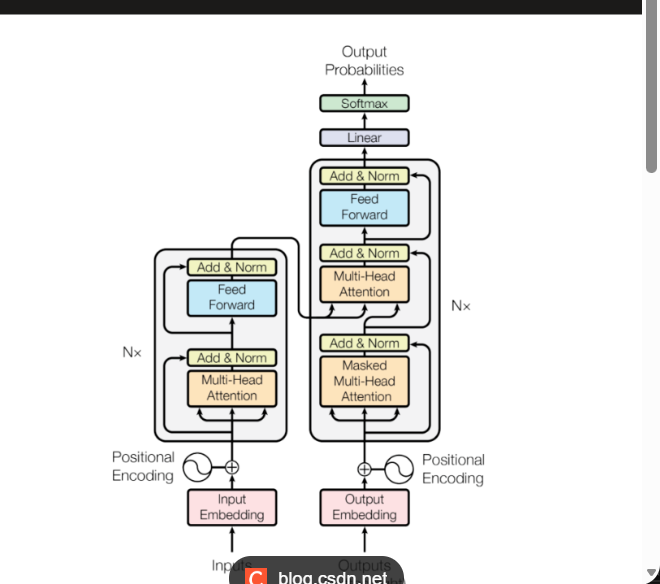

In [15]:
from dataclasses import dataclass
import torch
import torch.nn as nn
from torch.nn import functional as F
import math

'''
@dataclass让你用"声明字段"的方式定义一个数据类，
Python 自动补齐 __init__、__repr__、__eq__ 等样板代码，
写起来干净、读起来清楚。
'''

@dataclass
class GPTConfig:
    block_size: int = 256    # 上下文窗口最大长度，一次最多看256个token
    vocab_size: int = 65     # 词表大小，一共65个不同token
    n_layer: int = 6         # Transformer block层数
    n_head: int = 6          # 多头注意力的头数
    n_embd: int = 384        # 词嵌入维度，每个token映射成384维向量


In [16]:
class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        '''
        如果余数为 0（能整除），条件为 True，断言通过，程序继续。
        如果余数不为 0（不能整除），条件为 False，触发 AssertionError，程序中断。
        '''

        # 一个线性层同时计算 Q、K、V
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        # 多头拼接后的输出投影，把各头结果融合回 n_embd 维度
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        # regularization
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        # tril下三角（上三角是0）
        self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size))
                                     .view(1, 1, config.block_size, config.block_size))

    def forward(self, x):
        B, T, C = x.size() # batch size, sequence length, embedding dimensionality (n_embd)
        # calculate query, key, values for all heads in batch and move head forward to be the batch dim
        # nh is "number of heads", hs is "head size", and C (number of channels) = nh * hs
        # e.g. in GPT-2 (124M), n_head=12, hs=64, so nh*hs=C=768 channels in the Transformer
        qkv = self.c_attn(x)    #(B, T, 3*C) 
        q, k, v = qkv.split(self.n_embd, dim=2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)
        # attention (materializes the large (T,T) matrix for all the queries and keys)
        att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(k.size(-1)))  #k.size(-1) = head_size
        att = att.masked_fill(self.bias[:,:,:T,:T] == 0, float('-inf'))
        att = F.softmax(att, dim=-1)
        y = att @ v # (B, nh, T, T) x (B, nh, T, hs) -> (B, nh, T, hs)
        y = y.transpose(1, 2).contiguous().view(B, T, C) # re-assemble all head outputs side by side
        # output projection
        y = self.c_proj(y)
        return y

In [17]:
class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc    = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu    = nn.GELU(approximate='tanh')
        self.c_proj  = nn.Linear(4 * config.n_embd, config.n_embd)

    def forward(self, x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x

In [18]:
class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x)) # 残差 + 多头因果注意力
        x = x + self.mlp(self.ln_2(x))   # 残差 + MLP前馈网络
        return x

In [23]:
class GPT(nn.Module):
    def __init__(self, config): # <--- 这里的形参config
        super().__init__()
        self.config = config
        # 后面所有地方读取参数都靠 config.xxx
        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.n_embd),
            wpe = nn.Embedding(config.block_size, config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f = nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False) 

    def forward(self, idx):
        # idx is of shape (B, T)
        B, T = idx.size()
        assert T <= self.config.block_size, f"Cannot forward sequence of length {T}, block size is only {self.config.block_size}"
        # forward the token and position embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)  # shape (T)
        pos_emb = self.transformer.wpe(pos)  # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx)  # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layernorm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)  # (B, T, vocab_size)
        return logits

    @classmethod
    def from_pretrained(cls, model_type):
        """Loads pretrained GPT-2 model weights from huggingface"""
        assert model_type in {'gpt2', 'gpt2-medium', 'gpt2-large', 'gpt2-xl'}
        from transformers import GPT2LMHeadModel
        print("loading weights from pretrained gpt: %s" % model_type)

        # n_layer, n_head and n_embd are determined from model_type
        config_args = {
            'gpt2':         dict(n_layer=12, n_head=12, n_embd=768),   # 124M params
            'gpt2-medium':  dict(n_layer=24, n_head=16, n_embd=1024),  # 350M params
            'gpt2-large':   dict(n_layer=36, n_head=20, n_embd=1280),  # 774M params
            'gpt2-xl':      dict(n_layer=48, n_head=25, n_embd=1600),  # 1558M params
        }[model_type]
        config_args['vocab_size'] = 50257  # always 50257 for GPT model checkpoints
        config_args['block_size'] = 1024   # always 1024 for GPT model checkpoints
        # create a from-scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)
        sd = model.state_dict()
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')]  # discard this mask / buffer

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the parameters are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')]  # ignore these
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')]  # same, just the mask
        transposed = ['attn.c_attn.weight', 'attn.c_proj.weight', 'mlp.c_fc.weight', 'mlp.c_proj.weight']
        # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
            if any(k.endswith(w) for w in transposed):
                # special treatment for the Conv1D weights we need to transpose
                assert sd_hf[k].shape[::-1] == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k].t())
            else:
                # vanilla copy over the other parameters
                assert sd_hf[k].shape == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k])

        return model


In [24]:
model = GPT.from_pretrained('gpt2')
print("didn't crash yay!")

loading weights from pretrained gpt: gpt2


Could not reach the Hub ([Errno 110] Connection timed out). Using cached commit hash for 'gpt2'.
Loading weights: 100%|██████████| 148/148 [00:00<00:00, 13283.91it/s]

didn't crash yay!
